In [269]:
#from google.colab import drive
#drive.mount('/content/drive')

In [270]:
#%cd /content/drive/MyDrive/dataset

1. Import Required Libraries

In [271]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from imblearn.over_sampling import SMOTE
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.ensemble import GradientBoostingRegressor, BaggingRegressor

from sklearn.metrics import mean_squared_error, r2_score

sns.set(style="whitegrid")

2. Load the Dataset

In [272]:
df = pd.read_csv('/content/drive/MyDrive/dataset/HousePricePrediction.csv')

df.sample(5)

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2491,2491,20,RL,11075,Corner,1Fam,5,1984,1984,Wd Sdng,891.0,1190.0,NaN
1478,1478,20,RL,14122,Inside,1Fam,5,2005,2006,CemntBd,0.0,1822.0,NaN
751,751,60,RL,7750,Inside,1Fam,5,2003,2003,VinylSd,0.0,660.0,162000.0
1410,1410,60,RL,12420,Inside,1Fam,5,2001,2001,VinylSd,0.0,944.0,230000.0
1807,1807,50,RM,15660,Inside,1Fam,8,1910,2003,VinylSd,0.0,240.0,NaN


In [273]:
df.describe()

,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
count,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2918.000000,2918.000000,1460.000000
mean,1459.000000,57.137718,10168.114080,5.564577,1971.312778,1984.264474,49.582248,1051.777587,180921.195890
std,842.787043,42.517628,7886.996359,1.113131,30.291442,20.894344,169.205611,440.766258,79442.502883
min,0.000000,20.000000,1300.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,34900.000000
25%,729.500000,20.000000,7478.000000,5.000000,1953.500000,1965.000000,0.000000,793.000000,129975.000000
50%,1459.000000,50.000000,9453.000000,5.000000,1973.000000,1993.000000,0.000000,989.500000,163000.000000
75%,2188.500000,70.000000,11570.000000,6.000000,2001.000000,2004.000000,0.000000,1302.000000,214000.000000
max,2918.000000,190.000000,215245.000000,9.000000,2010.000000,2010.000000,1526.000000,6110.000000,755000.000000


In [274]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   object 
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   object 
 5   BldgType      2919 non-null   object 
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   object 
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), object(4)
memory usage: 296.6+ KB


In [275]:
df.duplicated().sum()

np.int64(0)

In [276]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,4
LotArea,0
LotConfig,0
BldgType,0
OverallCond,0
YearBuilt,0
YearRemodAdd,0
Exterior1st,1


In [277]:
df.shape

(2919, 13)

3. Exploratory Data Analysis (EDA)

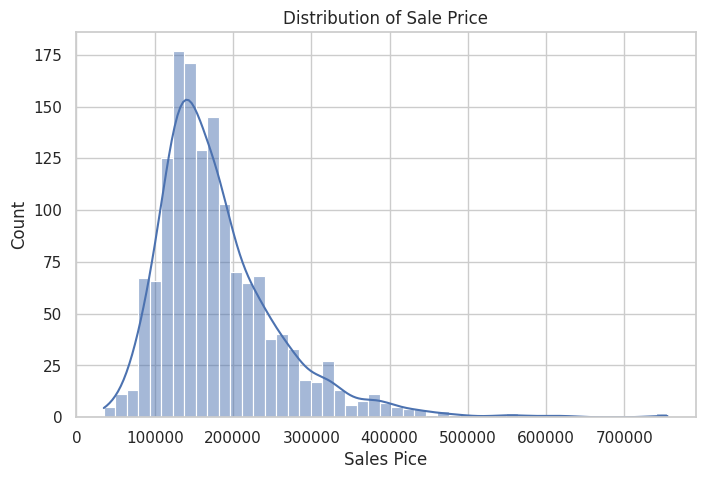

In [278]:
plt.figure(figsize=(8,5))
sns.histplot(df['SalePrice'],kde=True)
plt.title('Distribution of Sale Price')
plt.xlabel('Sales Pice')
plt.ylabel('Count')
plt.show()

In [279]:
df['SalePrice'].skew()

np.float64(1.8828757597682129)

Box Plot for Outlier Detection

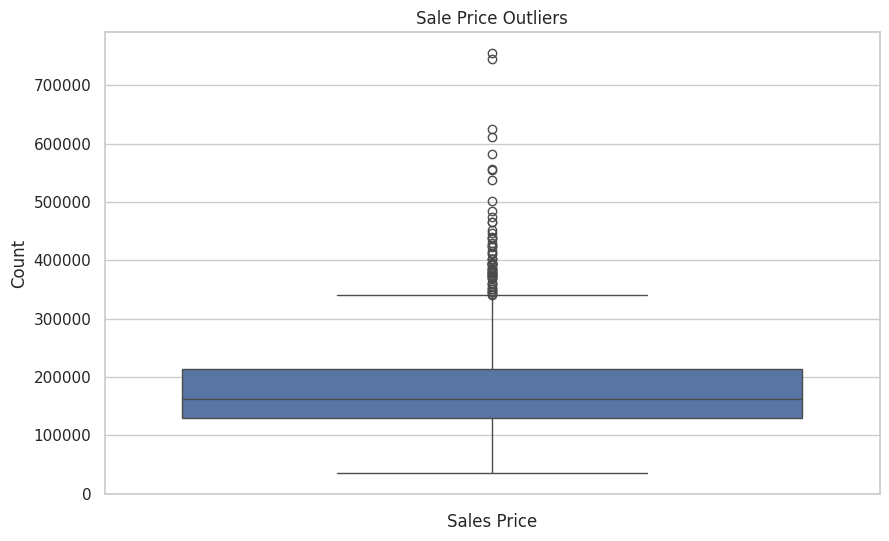

In [280]:
plt.figure(figsize=(10,6))
sns.boxplot(y=df['SalePrice'])
plt.title('Sale Price Outliers')
plt.xlabel('Sales Price')
plt.ylabel('Count')
plt.show()

Drop irrelevant columns

In [281]:
df = df.drop(columns=[
    "Id",
    "YearRemodAdd",
    "Exterior1st",
    "BsmtFinSF2"
])

In [282]:
df.shape

(2919, 9)

In [283]:
impute = KNNImputer(n_neighbors=3)
df['SalePrice'] = impute.fit_transform(df[['SalePrice']]).ravel()

In [284]:
df.isnull().sum()

,0
MSSubClass,0
MSZoning,4
LotArea,0
LotConfig,0
BldgType,0
OverallCond,0
YearBuilt,0
TotalBsmtSF,1
SalePrice,0


In [285]:
def PercentileOutlierRemover(df, column):
    Q1 = df[column].quantile(0.5)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    print(f"Total Rows in Dataset: {len(df)}")
    return df

In [286]:
new_df = PercentileOutlierRemover(df,'SalePrice')

Total Rows in Dataset: 2897


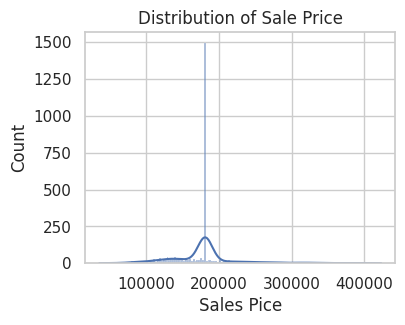

In [287]:
plt.figure(figsize=(4,3))
sns.histplot(new_df['SalePrice'],kde=True)
plt.title('Distribution of Sale Price')
plt.xlabel('Sales Pice')
plt.ylabel('Count')
plt.show()

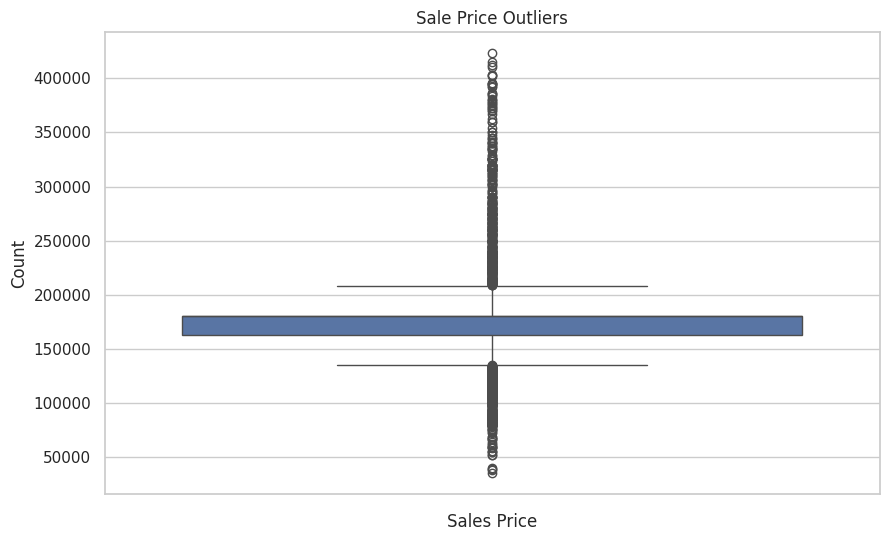

In [288]:
plt.figure(figsize=(10,6))
sns.boxplot(y=new_df['SalePrice'])
plt.title('Sale Price Outliers')
plt.xlabel('Sales Price')
plt.ylabel('Count')
plt.show()

In [289]:
X = new_df.drop(columns=['SalePrice'])
y = np.log1p(new_df['SalePrice'])

Train test Split

In [290]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [291]:
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

In [292]:
# Numerical: Missing values fill (KNN) -> Scaling (StandardScaler)
numerical_transformer = Pipeline(steps=[
    ('str_imputer', SimpleImputer(strategy='mean'))
])

In [293]:
# Categorical: Missing values fill -> One Hot Encoding
categorical_transformer = Pipeline(steps=[
    ('str_imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [294]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# **Pipeline Implementation for Different Models**

In [295]:
#LinearRegression ---> OLS method
pipeline1 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

pipeline1.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer())]),
                                                  ['MSSubClass', 'LotArea',
                                                   'OverallCond', 'YearBuilt',
                                                   'TotalBsmtSF']),
                                                 ('cat',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'LotConfig',
                                                   'BldgType'])])),
                ('model', LinearRegression())])

In [296]:
#LinearRegression --> Ridge(regularization) + Gradient Descent(optimization)
pipeline2 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=0.01, max_iter=5000, solver='saga'))
])

pipeline2.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer())]),
                                                  ['MSSubClass', 'LotArea',
                                                   'OverallCond', 'YearBuilt',
                                                   'TotalBsmtSF']),
                                                 ('cat',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'LotConfig',
                                                   'BldgType'])])),
                ('model', Ridge(alpha=0.01, max_iter=5000, solver='saga'))])

In [297]:
#LinearRegression --> Lasso(regularization) + Gradient Descent(optimization)
pipeline3 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=0.1, max_iter=1000))
])

pipeline3.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer())]),
                                                  ['MSSubClass', 'LotArea',
                                                   'OverallCond', 'YearBuilt',
                                                   'TotalBsmtSF']),
                                                 ('cat',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'LotConfig',
                                                   'BldgType'])])),
                ('model', Lasso(alpha=0.1))])

In [298]:
#LinearRegression --> ElasticNet(regularization) + Gradient Descent(optimization)
pipeline4 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', ElasticNet(alpha=0.01, l1_ratio=0.4, random_state=42,    max_iter=5000))
])

pipeline4.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer())]),
                                                  ['MSSubClass', 'LotArea',
                                                   'OverallCond', 'YearBuilt',
                                                   'TotalBsmtSF']),
                                                 ('cat',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'LotConfig',
                                                   'BldgType'])])),
                ('model',
                 ElasticNet(alpha=0.01, l1_ratio=0.4, max_iter=5000,
                            random_state=42))])

In [299]:
#LinearRegression --> Stocastic Gradient Descent with ridge
pipeline5 = Pipeline(steps=[
                ('preprocessor', preprocessor),
                ('model', SGDRegressor(penalty='l1',l1_ratio=1.0, max_iter=100000,learning_rate='constant',eta0=1e-10, alpha=1.0,early_stopping=True,n_iter_no_change=5,random_state=42))
            ])

pipeline5.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer())]),
                                                  ['MSSubClass', 'LotArea',
                                                   'OverallCond', 'YearBuilt',
                                                   'TotalBsmtSF']),
                                                 ('cat',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'LotConfig',
                                                   'BldgType'])])),
                ('model',
                 SGDRegressor(alpha=1.0, early_stopping=True, eta0=1e-10,
                              l1_ratio=1.0, learning_rate='constant',
                              max_iter=100000, penalty='l1',
                              random_state=42))])

In [300]:
pipeline6 = Pipeline(steps=[
                ('preprocessor', preprocessor),
                ('model', BaggingRegressor(estimator=LinearRegression(),bootstrap=True,bootstrap_features=False,max_features=1.0,max_samples=0.5,n_estimators=100,random_state=1))
            ])

pipeline6.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer())]),
                                                  ['MSSubClass', 'LotArea',
                                                   'OverallCond', 'YearBuilt',
                                                   'TotalBsmtSF']),
                                                 ('cat',
                                                  Pipeline(steps=[('str_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'LotConfig',
                                                   'BldgType'])])),
                ('model',
                 BaggingRegressor(estimator=LinearRegression(), max_samples=0.5,
                                  n_estimators=100, random_state=1))])

In [301]:
X_train.shape

(2317, 8)

In [302]:
#Prediction
y_pre1 = pipeline1.predict(X_test)
y_pre2 = pipeline2.predict(X_test)
y_pre3 = pipeline3.predict(X_test)
y_pre4 = pipeline4.predict(X_test)
y_pre5 = pipeline5.predict(X_test)
y_pre6 = pipeline6.predict(X_test)

**Calculate error and model score**

In [303]:
#LinearRegession MSE , R2_Score
mse = mean_squared_error(y_test, y_pre1)
r2_lr = r2_score(y_test, y_pre1)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2_lr}")

Mean Squared Error: 0.057412691276668336
R-squared: 0.2913280200211854


In [304]:
#Ridge MSE , R2_Score
mse = mean_squared_error(y_test, y_pre2)
r2_ridge = r2_score(y_test, y_pre2)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2_ridge}")

Mean Squared Error: 0.06692509858571886
R-squared: 0.1739118813213908


In [305]:
#Lasso MSE , R2_Score
mse = mean_squared_error(y_test, y_pre3)
r2_lasso = r2_score(y_test, y_pre3)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2_lasso}")

Mean Squared Error: 0.06090714192820817
R-squared: 0.24819436425453145


In [306]:
#ElasticNet MSE , R2_Score
mse = mean_squared_error(y_test, y_pre4)
r2_eln = r2_score(y_test, y_pre4)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2_eln}")

Mean Squared Error: 0.05751322552135431
R-squared: 0.29008707832949654


In [307]:
#SGDRegressor MSE , R2_Score
mse = mean_squared_error(y_test, y_pre5)
r2_sgd = r2_score(y_test, y_pre5)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2_sgd}")

Mean Squared Error: 0.06470081091723401
R-squared: 0.20136731514649353


In [308]:
#BaggingRegressor MSE , R2_Score
mse = mean_squared_error(y_test, y_pre6)
r2_bag = r2_score(y_test, y_pre6)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2_bag}")

Mean Squared Error: 0.05777680527787841
R-squared: 0.2868335888346716


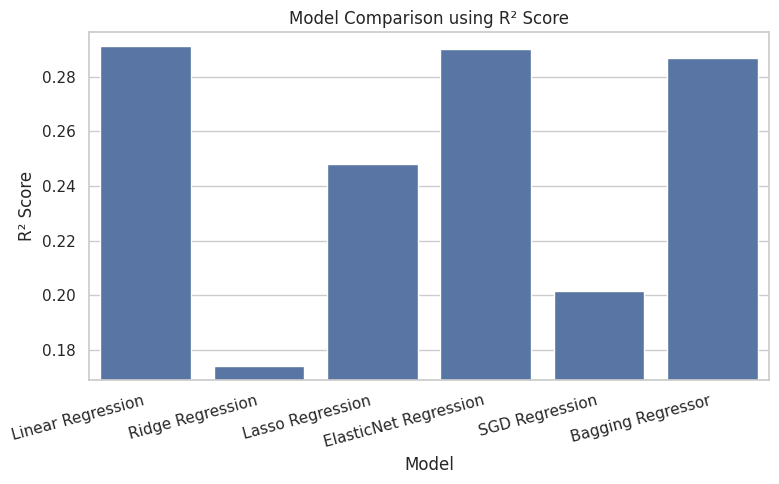

In [309]:
results_df = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression","ElasticNet Regression","SGD Regression", "Bagging Regressor"],
    "R2 Score": [r2_lr, r2_ridge, r2_lasso,r2_eln,r2_sgd,r2_bag]
})

results_df

r2_min = min([r2_lr, r2_ridge, r2_lasso, r2_eln, r2_sgd, r2_bag])
r2_max = max([r2_lr, r2_ridge, r2_lasso, r2_eln, r2_sgd, r2_bag])

#R² Score Comparison Visualization

plt.figure(figsize=(8, 5))
sns.barplot(
    x="Model",
    y="R2 Score",
    data=results_df
)
plt.title("Model Comparison using R² Score")
plt.ylabel("R² Score")
plt.ylim(r2_min - 0.005, r2_max + 0.005)

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()